# Import Libraries

In [1]:
# Data handling and visualization
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

# Modeling and evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict

# Imbalanced-data tools
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC

import json
import joblib


## Load data and make dataframe

In [2]:
DATA_PATH = Path("../data/raw/telco_customer_churn.csv")

df = pd.read_csv(DATA_PATH)
df.sample(5, random_state=15)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5545,Male,1,Yes,No,21,Yes,No,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,No,Bank transfer (automatic),86.55,1857.25,No
1657,Male,0,No,No,35,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,25.60,901.25,No
2218,Female,0,Yes,Yes,71,Yes,No,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),82.00,5999.85,No
4392,Male,0,Yes,Yes,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.20,19.2,No
1461,Male,0,Yes,No,22,Yes,Yes,Fiber optic,Yes,No,No,Yes,Yes,No,Month-to-month,No,Credit card (automatic),95.90,2234.95,No


# EDA  

In [3]:
print("Shape:", df.shape)
print("*"*60 )
df.info()
print("*"*60 )
print(df['Churn'].value_counts())
print("*"*60 )
print(df['Churn'].value_counts(normalize=True).round(3))

Shape: (7043, 20)
************************************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessB

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
print("Missing values (NaN):", df.isnull().sum().sum())

blank_mask = df['TotalCharges'].str.strip() == ''
print("Blank TotalCharges:", blank_mask.sum())

df.loc[blank_mask, ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Missing values (NaN): 0
Blank TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [6]:
df = df.copy()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip().replace('', '0'))

print(df['TotalCharges'].dtype)
print(df.shape)
print(df.loc[blank_mask, ['tenure', 'TotalCharges']].head(3))

float64
(7043, 20)
     tenure  TotalCharges
488       0           0.0
753       0           0.0
936       0           0.0


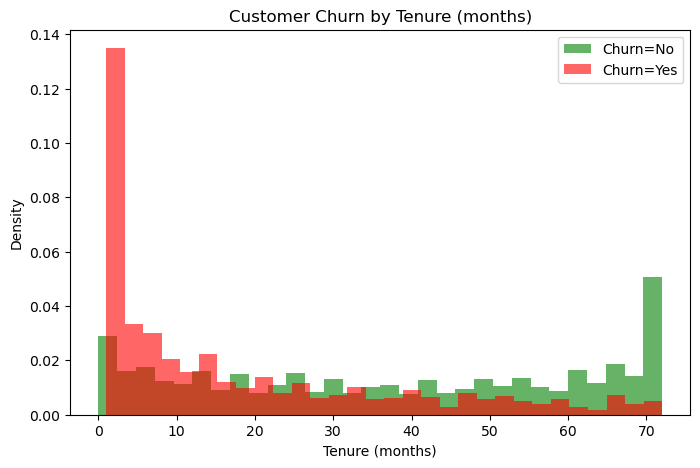

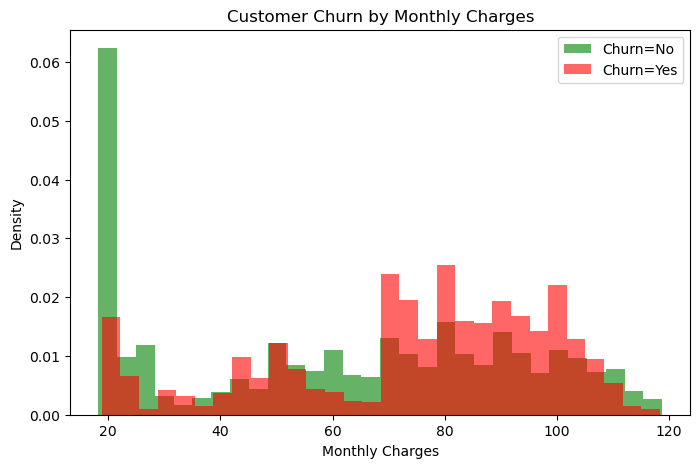

In [7]:
def plot_churn_hist(df, column, xlabel):
    churned = df.loc[df['Churn'] == 'Yes', column]
    stayed = df.loc[df['Churn'] == 'No', column]

    plt.figure(figsize=(8, 5))
    plt.hist(stayed, bins=30, alpha=0.6, density=True, color='green', label='Churn=No')
    plt.hist(churned, bins=30, alpha=0.6, density=True, color='red', label='Churn=Yes')
    plt.xlabel(xlabel)
    plt.ylabel("Density")
    plt.title(f"Customer Churn by {xlabel}")
    plt.legend()
    plt.show()


plot_churn_hist(df, 'tenure', 'Tenure (months)')
plot_churn_hist(df, 'MonthlyCharges', 'Monthly Charges')

# Data Preprocessing

In [8]:
def print_unique_col_values(data):
    for column in data.select_dtypes(include='object'):
        print(f"{column}: {data[column].unique()}")


print_unique_col_values(df)

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


In [9]:
internet_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']

df[internet_cols] = df[internet_cols].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

print_unique_col_values(df)

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes']
OnlineBackup: ['Yes' 'No']
DeviceProtection: ['No' 'Yes']
TechSupport: ['No' 'Yes']
StreamingTV: ['No' 'Yes']
StreamingMovies: ['No' 'Yes']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


In [10]:
yes_no_columns = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                  'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                  'TechSupport', 'StreamingTV', 'StreamingMovies',
                  'PaperlessBilling']

for col in yes_no_columns:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("NaN after mapping:", df.isnull().sum().sum())
print_unique_col_values(df)

NaN after mapping: 0
InternetService: ['DSL' 'Fiber optic' 'No']
Contract: ['Month-to-month' 'One year' 'Two year']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [11]:
df_encoded = pd.get_dummies(
    df, columns=['Contract', 'PaymentMethod', 'InternetService'], dtype=int
)

print(df_encoded.shape)
print(df_encoded.columns.tolist())

df_encoded.filter(like='Contract_').head(3)

(7043, 27)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No']


,Contract_Month-to-month,Contract_One year,Contract_Two year
0,1,0,0
1,0,1,0
2,1,0,0


In [12]:
X = df.drop(columns='Churn')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=15, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate (train):", round(y_train.mean(), 3))
print("Churn rate (test):", round(y_test.mean(), 3))

Train: (5634, 19) | Test: (1409, 19)
Churn rate (train): 0.265
Churn rate (test): 0.265


In [13]:
for col in ['Contract', 'PaymentMethod', 'InternetService']:
    print(col, "-> missing from train:", set(X_test[col]) - set(X_train[col]))

Contract -> missing from train: set()
PaymentMethod -> missing from train: set()
InternetService -> missing from train: set()


In [14]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

categorical_cols = ['Contract', 'PaymentMethod', 'InternetService']

binary_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
               'PhoneService', 'MultipleLines', 'OnlineSecurity',
               'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'PaperlessBilling']

categories = [
    ['Month-to-month', 'One year', 'Two year'],
    ['Bank transfer (automatic)', 'Credit card (automatic)',
     'Electronic check', 'Mailed check'],
    ['DSL', 'Fiber optic', 'No'],
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), numeric_cols),
        ('cat', OneHotEncoder(categories=categories,
                              handle_unknown='ignore',
                              sparse_output=False), categorical_cols),
        ('bin', 'passthrough', binary_cols),
    ]
)
preprocessor.set_output(transform='pandas')

,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,feature_range,"(0, ...)"
,copy,True
,clip,False


In [15]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)
print(X_train_prep.columns.tolist())
print(X_train_prep[['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges']]
      .describe().loc[['min', 'max']])

(5634, 26) (1409, 26)
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__Contract_Month-to-month', 'cat__Contract_One year', 'cat__Contract_Two year', 'cat__PaymentMethod_Bank transfer (automatic)', 'cat__PaymentMethod_Credit card (automatic)', 'cat__PaymentMethod_Electronic check', 'cat__PaymentMethod_Mailed check', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'bin__gender', 'bin__SeniorCitizen', 'bin__Partner', 'bin__Dependents', 'bin__PhoneService', 'bin__MultipleLines', 'bin__OnlineSecurity', 'bin__OnlineBackup', 'bin__DeviceProtection', 'bin__TechSupport', 'bin__StreamingTV', 'bin__StreamingMovies', 'bin__PaperlessBilling']
     num__tenure  num__MonthlyCharges  num__TotalCharges
min          0.0                  0.0                0.0
max          1.0                  1.0                1.0


# Train Models and Cross Validation

In [16]:
def build_pipeline(class_weight=None):
    return Pipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(class_weight=class_weight,
                                     max_iter=1000, random_state=15)),
    ])


def evaluate(pipe, X_train, y_train, X_test, y_test):
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    print("Accuracy:", round(pipe.score(X_test, y_test), 3))
    print(classification_report(y_test, y_pred))
    return pipe


pipe_base = evaluate(build_pipeline(), X_train, y_train, X_test, y_test)

Accuracy: 0.798
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [17]:
print("--- class_weight = {0: 1, 1: 1.5} ---")
pipe_w15 = evaluate(build_pipeline(class_weight={0: 1, 1: 1.5}),
                    X_train, y_train, X_test, y_test)

print("--- class_weight = 'balanced' ---")
pipe_bal = evaluate(build_pipeline(class_weight='balanced'),
                    X_train, y_train, X_test, y_test)

--- class_weight = {0: 1, 1: 1.5} ---
Accuracy: 0.793
              precision    recall  f1-score   support

           0       0.87      0.84      0.86      1035
           1       0.60      0.65      0.63       374

    accuracy                           0.79      1409
   macro avg       0.74      0.75      0.74      1409
weighted avg       0.80      0.79      0.80      1409

--- class_weight = 'balanced' ---
Accuracy: 0.736
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.77      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.74      0.75      1409



In [18]:
def build_sampling_pipeline(sampler):
    return ImbPipeline([
        ('prep', preprocessor),
        ('sampler', sampler),
        ('model', LogisticRegression(max_iter=1000, random_state=15)),
    ])


print("--- Undersampling ---")
pipe_under = evaluate(build_sampling_pipeline(RandomUnderSampler(random_state=15)),
                      X_train, y_train, X_test, y_test)

print("--- Oversampling ---")
pipe_over = evaluate(build_sampling_pipeline(RandomOverSampler(random_state=15)),
                     X_train, y_train, X_test, y_test)

--- Undersampling ---
Accuracy: 0.74
              precision    recall  f1-score   support

           0       0.89      0.73      0.81      1035
           1       0.51      0.76      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.75      1409

--- Oversampling ---
Accuracy: 0.736
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1035
           1       0.50      0.76      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.74      0.75      1409



In [19]:
def build_smotenc_pipeline():
    cat_features = categorical_cols + binary_cols
    return ImbPipeline([
        ('sampler', SMOTENC(categorical_features=cat_features, random_state=15)),
        ('prep', clone(preprocessor)),
        ('model', LogisticRegression(max_iter=1000, random_state=15)),
    ])


print("--- SMOTENC ---")
pipe_smote = evaluate(build_smotenc_pipeline(), X_train, y_train, X_test, y_test)

--- SMOTENC ---
Accuracy: 0.76
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In [20]:
def build_pipeline(class_weight=None):
    return Pipeline([
        ('prep', clone(preprocessor)),
        ('model', LogisticRegression(class_weight=class_weight,
                                     max_iter=1000, random_state=15)),
    ])


def build_sampling_pipeline(sampler):
    return ImbPipeline([
        ('prep', clone(preprocessor)),
        ('sampler', sampler),
        ('model', LogisticRegression(max_iter=1000, random_state=15)),
    ])


def build_smotenc_pipeline():
    cat_features = categorical_cols + binary_cols
    return ImbPipeline([
        ('sampler', SMOTENC(categorical_features=cat_features, random_state=15)),
        ('prep', clone(preprocessor)),
        ('model', LogisticRegression(max_iter=1000, random_state=15)),
    ])


pipe_base = evaluate(build_pipeline(), X_train, y_train, X_test, y_test)

Accuracy: 0.798
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=15)

scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
}

models = {
    'No weight': build_pipeline(),
    'Weight 1.5': build_pipeline(class_weight={0: 1, 1: 1.5}),
    'Balanced': build_pipeline(class_weight='balanced'),
    'Undersampling': build_sampling_pipeline(RandomUnderSampler(random_state=15)),
    'Oversampling': build_sampling_pipeline(RandomOverSampler(random_state=15)),
    'SMOTENC': build_smotenc_pipeline(),
}

rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {'model': name}
    for metric in scoring:
        values = scores[f'test_{metric}']
        row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index('model')
cv_results

,precision,recall,f1,roc_auc,pr_auc
model,,,,,
No weight,0.656 ± 0.016,0.557 ± 0.012,0.602 ± 0.006,0.849 ± 0.010,0.660 ± 0.019
Weight 1.5,0.590 ± 0.017,0.663 ± 0.024,0.624 ± 0.016,0.849 ± 0.010,0.659 ± 0.019
Balanced,0.523 ± 0.016,0.805 ± 0.012,0.634 ± 0.013,0.849 ± 0.009,0.658 ± 0.017
Undersampling,0.524 ± 0.016,0.807 ± 0.018,0.635 ± 0.013,0.847 ± 0.009,0.655 ± 0.016
Oversampling,0.523 ± 0.015,0.811 ± 0.012,0.636 ± 0.012,0.848 ± 0.010,0.656 ± 0.018
SMOTENC,0.540 ± 0.018,0.751 ± 0.019,0.628 ± 0.014,0.840 ± 0.009,0.637 ± 0.017


In [22]:
def build_model_pipeline(model):
    return Pipeline([
        ('prep', clone(preprocessor)),
        ('model', model),
    ])


def cv_table(models, scoring):
    rows = []
    for name, pipe in models.items():
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        row = {'model': name}
        for metric in scoring:
            values = scores[f'test_{metric}']
            row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index('model')


auc_scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}

candidates = {
    'Logistic (baseline)': build_pipeline(),
    'Random Forest': build_model_pipeline(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                               random_state=15, n_jobs=-1)),
    'Gradient Boosting': build_model_pipeline(
        HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200,
                                       random_state=15)),
}

cv_table(candidates, auc_scoring)

,roc_auc,pr_auc
model,,
Logistic (baseline),0.849 ± 0.010,0.660 ± 0.019
Random Forest,0.848 ± 0.012,0.659 ± 0.024
Gradient Boosting,0.835 ± 0.014,0.634 ± 0.025


In [23]:
final_pipe = build_pipeline()

oof_proba = cross_val_predict(final_pipe, X_train, y_train,
                              cv=cv, method='predict_proba')[:, 1]

COST_MISSED_CHURN = 200
COST_FALSE_ALARM = 50

y_true = y_train.to_numpy()
rows = []
for t in np.arange(0.05, 0.80, 0.05):
    pred = (oof_proba >= t).astype(int)
    tp = ((pred == 1) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    rows.append({
        'threshold': round(t, 2),
        'recall': tp / (tp + fn),
        'precision': tp / (tp + fp),
        'total_cost': fn * COST_MISSED_CHURN + fp * COST_FALSE_ALARM,
    })

threshold_df = pd.DataFrame(rows).set_index('threshold')
best_threshold = threshold_df['total_cost'].idxmin()
print("Best threshold:", best_threshold)
threshold_df.round(3)

Best threshold: 0.2


,recall,precision,total_cost
threshold,,,
0.05,0.977,0.360,136600
0.10,0.946,0.402,121200
0.15,0.914,0.441,112400
0.20,0.868,0.480,109750
0.25,0.821,0.512,112050
0.30,0.771,0.542,117250
0.35,0.710,0.563,127950
0.40,0.661,0.590,135750
0.45,0.604,0.620,146100


In [24]:
final_pipe.fit(X_train, y_train)
test_proba = final_pipe.predict_proba(X_test)[:, 1]
y_test_arr = y_test.to_numpy()

print("Test ROC-AUC:", round(roc_auc_score(y_test_arr, test_proba), 3))
print("Test PR-AUC:", round(average_precision_score(y_test_arr, test_proba), 3))


def cost_report(proba, y_true, t):
    pred = (proba >= t).astype(int)
    tp = ((pred == 1) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    return {
        'recall': round(tp / (tp + fn), 3),
        'precision': round(tp / (tp + fp), 3),
        'total_cost': int(fn * COST_MISSED_CHURN + fp * COST_FALSE_ALARM),
    }


n_churn = int(y_test_arr.sum())
n_stay = len(y_test_arr) - n_churn

final_table = pd.DataFrame({
    'No model (contact nobody)': {'recall': 0.0, 'precision': None,
                                  'total_cost': n_churn * COST_MISSED_CHURN},
    'Contact everyone': {'recall': 1.0, 'precision': round(n_churn / len(y_test_arr), 3),
                         'total_cost': n_stay * COST_FALSE_ALARM},
    'Model, threshold 0.5': cost_report(test_proba, y_test_arr, 0.5),
    f'Model, threshold {best_threshold}': cost_report(test_proba, y_test_arr, best_threshold),
}).T

final_table

Test ROC-AUC: 0.828
Test PR-AUC: 0.628


,recall,precision,total_cost
No model (contact nobody),0.000,NaN,74800.0
Contact everyone,1.000,0.265,51750.0
"Model, threshold 0.5",0.511,0.652,41700.0
"Model, threshold 0.2",0.810,0.454,32450.0


In [25]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(final_pipe, MODEL_DIR / "churn_pipeline.joblib")

metadata = {
    "threshold": float(best_threshold),
    "cost_missed_churn": COST_MISSED_CHURN,
    "cost_false_alarm": COST_FALSE_ALARM,
    "feature_columns": X_train.columns.tolist(),
    "test_roc_auc": round(roc_auc_score(y_test_arr, test_proba), 3),
    "test_pr_auc": round(average_precision_score(y_test_arr, test_proba), 3),
}
with open(MODEL_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

loaded = joblib.load(MODEL_DIR / "churn_pipeline.joblib")
print("Same predictions after reload:",
      np.allclose(loaded.predict_proba(X_test)[:, 1], test_proba))

Same predictions after reload: True


# Conclusion

The target is imbalanced (~73% stayed, ~27% churned), so accuracy alone is misleading.

**Key findings (5-fold stratified CV on the training set, then one final test evaluation):**

- Class weights, under/over-sampling and SMOTENC did not improve ranking quality
  (ROC-AUC ≈ 0.85, PR-AUC ≈ 0.66 for all, SMOTENC slightly worse). They only shift
  the operating point, trading precision for recall.
- Logistic regression matched Random Forest and beat Gradient Boosting, so the simpler,
  interpretable model was selected.
- The decision threshold was chosen on out-of-fold predictions using an assumed cost
  (200 per lost customer, 50 per unnecessary retention offer): threshold = 0.2.

**Final test results (1,409 customers, threshold 0.2):**

| Strategy | Recall | Precision | Total cost |
|---|---|---|---|
| Contact nobody | 0.000 | - | 74,800 |
| Contact everyone | 1.000 | 0.265 | 51,750 |
| Model, threshold 0.5 | 0.511 | 0.652 | 41,700 |
| **Model, threshold 0.2** | **0.810** | **0.454** | **32,450** |

Test ROC-AUC: 0.828, PR-AUC: 0.628. Costs are assumptions, not real business data.